# 1. Street identity: turning OSM ways into streets

OSM splits a street into a new way at every intersection. Named
streets aren't a problem because the `name` tag already identifies
them. Unnamed streets are a problem. Without correction, every segment
between two intersections looks like a separate street.

`osmaddresssystem.street_ids.label_streets(G)` fixes this. It assigns
every edge a `street_id`, keeping the same id for an unnamed street as
it crosses intersections.

This notebook shows each rule on tiny hand-built graphs, then applies
the same function to a synthetic street grid.

In [1]:
import matplotlib.pyplot as plt
from _tutorial_utils import (
    add_oneway_edge, arm, build_idealized_grid, build_irregular_grid, label, make_graph,
    new_graph, plot_streets,
)

plt.rcParams["figure.dpi"] = 110

## Rule 1: named streets are left as-is

A named edge keeps its name as its identity. No geometry is checked.
Below, three collinear segments share the tag `name="Elm Street"`.
They get one `street_id` because of that shared name alone.

,street_id,street_name,street_rank,highway,osmids
0,1,Elm Street,5,residential,1


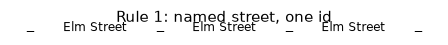

In [2]:
G = make_graph([
    (0, 1, (0, 0), (100, 0), "residential", "Elm Street"),
    (1, 2, (100, 0), (200, 0), "residential", "Elm Street"),
    (2, 3, (200, 0), (300, 0), "residential", "Elm Street"),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Rule 1: named street, one id")
plt.show()

### Fuzzy name matching

Rule 1 doesn't just check that two names are identical. Two edges
merge when their names *fuzzy-match*, so real-world naming quirks
don't split one street into several ids. The clearest example: a route
is sometimes tagged by its route number ("Nationale 5") and sometimes
by the two towns it connects, with the number folded into a
parenthetical ("Douala-Bafoussam (N5)"). Both segments below share a
node, and their names fuzzy-match (see
[`osmaddresssystem/name_matching.py`](../../osmaddresssystem/name_matching.py)),
so they get one street_id despite having almost no characters in
common.

,street_id,street_name,street_rank,highway,osmids
0,1,Nationale 5,2,primary,1


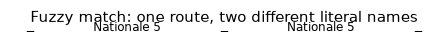

In [3]:
G = make_graph([
    (0, 1, (0, 0), (2000, 0), "primary", "Nationale 5"),
    (1, 2, (2000, 0), (4000, 0), "primary", "Douala-Bafoussam (N5)"),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Fuzzy match: one route, two different literal names")
plt.show()

### Same name, but never touching, stays separate

A shared name alone is no longer enough on its own: two edges named
"Elm Street" on opposite sides of town, with no chain of touching,
matching-name edges between them, get *different* street_ids. Compare
this to the merge above. The only difference is that these two edges
don't share a node.

,street_id,street_name,street_rank,highway,osmids
0,1,Elm Street,5,residential,1
1,2,Elm Street,5,residential,1


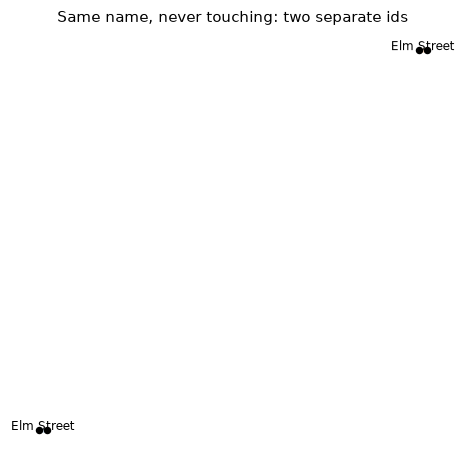

In [4]:
G = make_graph([
    (0, 1, (0, 0), (200, 0), "residential", "Elm Street"),
    (10, 11, (10_000, 10_000), (10_200, 10_000), "residential", "Elm Street"),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Same name, never touching: two separate ids")
plt.show()

### More than two same-name arms: still at most two share an id

A Y-fork where all three arms carry the exact same name is a real
OSM pattern (a route that keeps its name through what's really a
junction with a side road of the same name). Rule 1 still only merges
two edges at any one node, best match first, exactly like rule 4 for
unnamed edges. So the third arm is cut into its own id rather than
all three sharing one.

,street_id,street_name,street_rank,highway,osmids
0,1,Main Street,5,residential,1
1,2,Main Street,5,residential,1


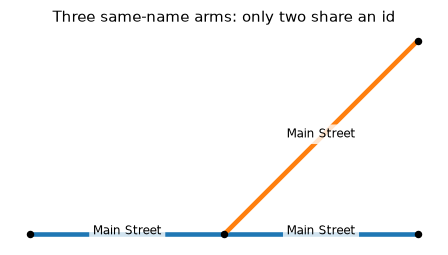

In [5]:
G = make_graph([
    (1, 0, (-300, 0), (0, 0), "residential", "Main Street"),
    (0, 2, (0, 0), (300, 0), "residential", "Main Street"),
    (0, 3, (0, 0), (300, 300), "residential", "Main Street"),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Three same-name arms: only two share an id")
plt.show()

## Rules 2 and 3: rank tiers, and equal-rank streets grouped by direction

At each intersection, incident edges are bucketed by highway type into
rank tiers. Only the dominant tier (the highest-priority tier present
at that node) is considered for merging there.

Within the dominant tier, two edges merge if their directions agree
within `angle_threshold_deg` (default 20°, measured mod 180° since a
street has no direction sense).

Below is a plus-shaped crossing of four unnamed `residential` arms.
All four are the same rank, so the whole tier is dominant. The
east/west arms are 0° apart and merge into one street. The north/south
arms merge into a different street. East/west and north/south never
merge with each other because they differ by 90°.

,street_id,street_name,street_rank,highway,osmids
0,1,None,5,residential,1
1,2,None,5,residential,1


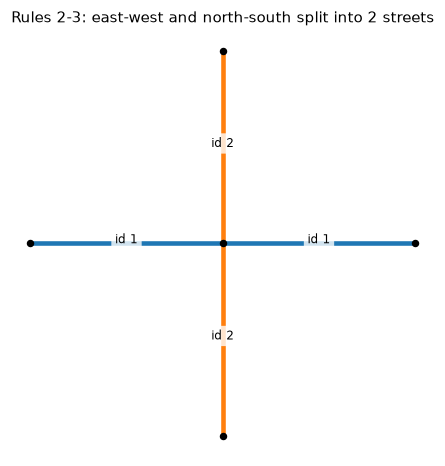

In [6]:
G = make_graph([
    (1, 0, (-100, 0), (0, 0), "residential", None),   # west arm
    (0, 2, (0, 0), (100, 0), "residential", None),    # east arm
    (0, 3, (0, 0), (0, 100), "residential", None),    # north arm
    (0, 4, (0, 0), (0, -100), "residential", None),   # south arm
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Rules 2-3: east-west and north-south split into 2 streets")
plt.show()

## Rule 2 continued: a lower-rank street is cut by a higher-rank crossing

Same plus shape, but now the east/west arms are `primary` and the
north/south arms are unnamed `residential`. Only the dominant tier can
merge across the node. The primary road keeps one identity through the
crossing. The two residential arms don't join the primary's id, and
they don't merge with each other either, even though they're collinear
and equal rank. Being crossed by a higher-rank street cuts a
lower-rank street into two ids.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,1
1,2,None,5,residential,1
2,3,None,5,residential,1


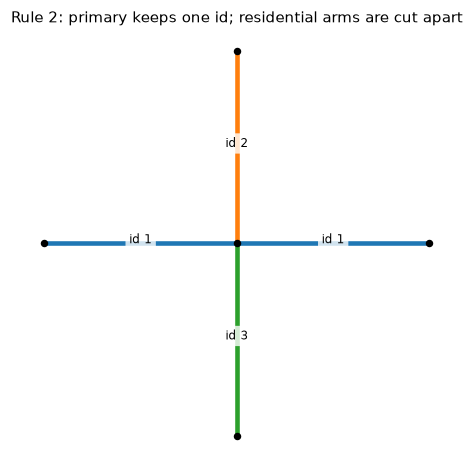

In [7]:
G = make_graph([
    (1, 0, (-100, 0), (0, 0), "primary", None),
    (0, 2, (0, 0), (100, 0), "primary", None),
    (0, 3, (0, 0), (0, 100), "residential", None),
    (0, 4, (0, 0), (0, -100), "residential", None),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Rule 2: primary keeps one id; residential arms are cut apart")
plt.show()

## Rule 4: best match wins, not first match

Four unnamed residential arms meet at one node, at 0°, 5°, 12°, and
70°. Matching is greedy by smallest angle difference first, and each
edge merges with at most one partner per node.

0° and 5° are the closest pair, so they merge first. 12° is within 20°
of both 0° and 5°, but they're already taken, so 12° stays on its own.
70° is far from everything and always stays separate.

The result is 3 streets from 4 arms, decided by closest pair first.

,street_id,street_name,street_rank,highway,osmids
0,1,None,5,residential,1
1,2,None,5,residential,1
2,3,None,5,residential,1


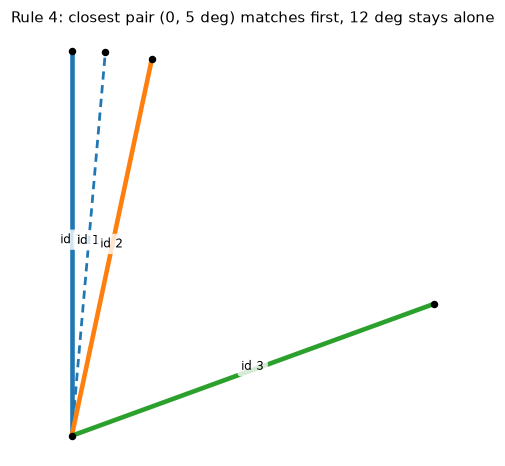

In [8]:
G = make_graph([
    (0, 1, (0, 0), arm(0), "residential", None),
    (0, 2, (0, 0), arm(5), "residential", None),
    (0, 3, (0, 0), arm(12), "residential", None),
    (0, 4, (0, 0), arm(70), "residential", None),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Rule 4: closest pair (0, 5 deg) matches first, 12 deg stays alone")
plt.show()

## Rule 5: no match, no merge

Two unnamed residential arms meet at 45° from each other, outside the
20° threshold. Neither inherits the other's identity. Each keeps its
own `street_id`.

,street_id,street_name,street_rank,highway,osmids
0,1,None,5,residential,1
1,2,None,5,residential,1


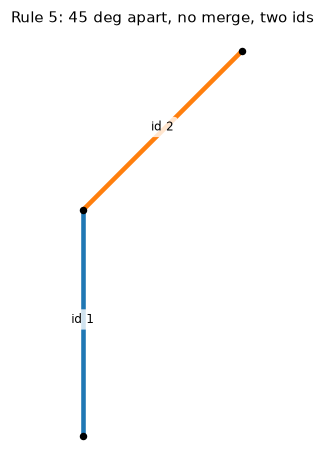

In [9]:
G = make_graph([
    (1, 0, arm(180), (0, 0), "residential", None),
    (0, 2, (0, 0), arm(45), "residential", None),
])
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Rule 5: 45 deg apart, no merge, two ids")
plt.show()

## Weird real-world cases: node clustering

A single real intersection is often mapped as *more than one* graph
node a few meters apart, most commonly where a divided road's two
carriageways separate or rejoin. `label_streets`'s `node_cluster_m`
argument (default 15m) groups graph nodes within that distance of each
other into a shared cluster, used by the two rules below. The examples
here build one-way edges directly with `new_graph`/`add_oneway_edge`,
since a divided road's two carriageways are two separate one-way ways,
not one reversible street the way `make_graph`'s edges are.

### A divided avenue: two carriageways, one street

Picture a wide avenue mapped as two separate one-way ways, one for
each direction, that happen to fork apart by a few meters at each end
(a planted median, a service lane). Their endpoints cluster together
in pairs, so they're recognized as the same street automatically. No
name or rank is needed at all. One of the two is flagged
`is_main_direction=True` (drawn solid below), and the other is `False`
(drawn thinner and dashed). That's just a tie-break for bookkeeping,
not a street-numbering direction.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,201;202


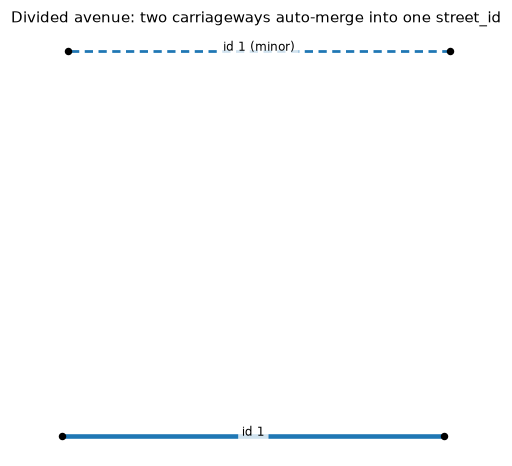

In [10]:
G = new_graph()
add_oneway_edge(G, 1, 3, (0, 0), (200, 0), highway="primary", osmid=201)
add_oneway_edge(G, 4, 2, (203, 6), (3, 6), highway="primary", osmid=202)

nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, show_main_direction=True, equal_aspect=False,
             title="Divided avenue: two carriageways auto-merge into one street_id")
plt.show()

Setting `node_cluster_m=0` disables clustering entirely, so the same
two carriageways are just two unrelated, unnamed edges. Two separate
ids, and no `is_main_direction=False` at all.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,201
1,2,None,2,primary,202


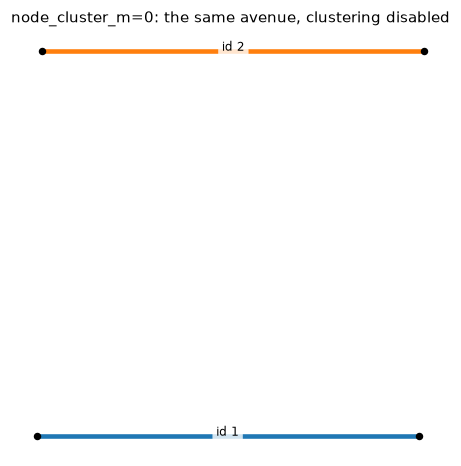

In [11]:
nodes_gdf, edges_gdf, streets_df = label(G, node_cluster_m=0)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, show_main_direction=True, equal_aspect=False,
             title="node_cluster_m=0: the same avenue, clustering disabled")
plt.show()

### An uneven divided avenue: `parallel_dist_m`

A divided avenue isn't always mapped symmetrically. Here one direction
is a single long way; the other is chopped into three shorter ways, and
the whole side is offset 20m from the first - past the default 15m
`node_cluster_m` radius, so none of its own endpoints cluster with any
single node of the long side. Node-cluster-based dual-carriageway
detection (above) never fires. `parallel_dist_m` generalizes that check
to a distance-and-angle test instead of an exact node match: two edges
merge if they're close (`parallel_dist_m`), running the same direction
(`parallel_angle_threshold_deg`, a separate threshold from
`angle_threshold_deg`), and reachable from each other within
`parallel_max_hops` hops of the street graph. That last part matters: a
short, unrelated cross-street (a median crossover, in real-world terms)
links the two sides below - without some real connection between them,
two edges that just happen to be close and parallel shouldn't merge
(see the footway example further down). `parallel_dist_m` is disabled
(`0`) by default; a reasonable value for a divided urban avenue is
25-30m.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,201;202;203
1,2,None,2,primary,204
2,3,None,5,residential,205


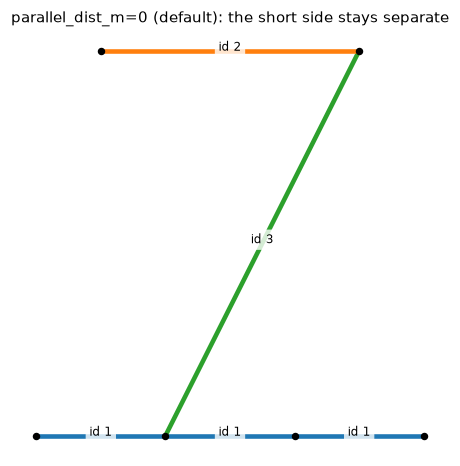

In [12]:
G = new_graph()
add_oneway_edge(G, 1, 2, (0, 0), (100, 0), highway="primary", osmid=201)
add_oneway_edge(G, 2, 3, (100, 0), (200, 0), highway="primary", osmid=202)
add_oneway_edge(G, 3, 4, (200, 0), (300, 0), highway="primary", osmid=203)
add_oneway_edge(G, 5, 6, (250, 20), (50, 20), highway="primary", osmid=204)
add_oneway_edge(G, 2, 5, (100, 0), (250, 20), highway="residential", osmid=205)

nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, equal_aspect=False,
             title="parallel_dist_m=0 (default): the short side stays separate")
plt.show()

With `parallel_dist_m=30`, the short side is close to, parallel with,
and (via the cross-street) reachable from the long side, so it merges
into the same `street_id` - the cross-street itself stays separate
(different name/rank, so it's not eligible).

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,201;202;203;204
1,2,None,5,residential,205


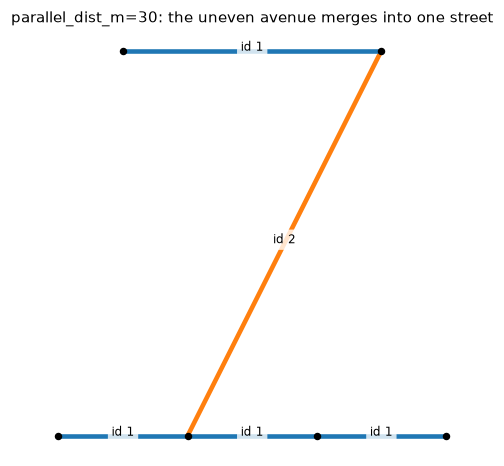

In [13]:
nodes_gdf, edges_gdf, streets_df = label(G, parallel_dist_m=30.0)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, equal_aspect=False,
             title="parallel_dist_m=30: the uneven avenue merges into one street")
plt.show()

It only merges into a street of the *same* dominant rank when unnamed,
so a footway running just as close and just as reachable alongside a
primary avenue isn't swept into the avenue's identity.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,301


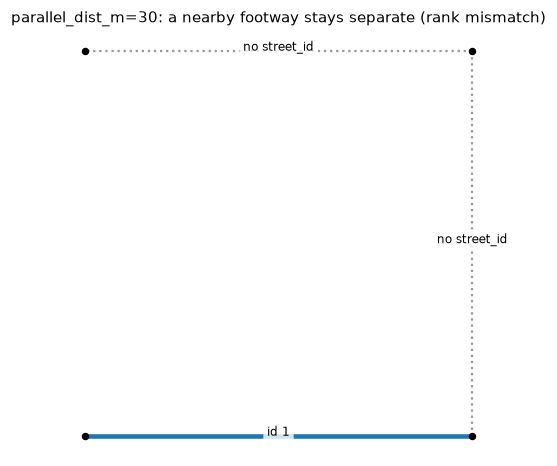

In [14]:
G = new_graph()
add_oneway_edge(G, 1, 2, (0, 0), (100, 0), highway="primary", osmid=301)
add_oneway_edge(G, 5, 6, (100, 20), (0, 20), highway="footway", osmid=302)
add_oneway_edge(G, 2, 5, (100, 0), (100, 20), highway="footway", osmid=303)

nodes_gdf, edges_gdf, streets_df = label(G, parallel_dist_m=30.0)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, equal_aspect=False,
             title="parallel_dist_m=30: a nearby footway stays separate (rank mismatch)")
plt.show()

### A busy intersection splits a named street - and `parallel_dist_m` rescues it

This is the real-world case that motivated `parallel_dist_m` beyond
divided avenues (found by checking `label_streets`'s output against a
real OSM extract - see
[`tests/test_street_ids_real_data.py`](../../tests/test_street_ids_real_data.py)):
three directly-chained, identically-named edges (a straight street
through two crossings) end up with different `street_id`s, because a
short middle segment happens to be within `node_cluster_m` of the next
node - a "crossing" node in the real data - making it a loop/connector
edge that regular name-matching skips entirely (see "Node clustering"
above), and a same-named side street also touching that node gives the
connector-bridging step two different candidates to choose between
instead of the one obviously-correct answer.

,street_id,street_name,street_rank,highway,osmids
0,1,Calle de Fernández de la Hoz,5,residential,1;2
1,2,Calle Santa Engracia,5,residential,4
2,3,Calle de Fernández de la Hoz,5,residential,3


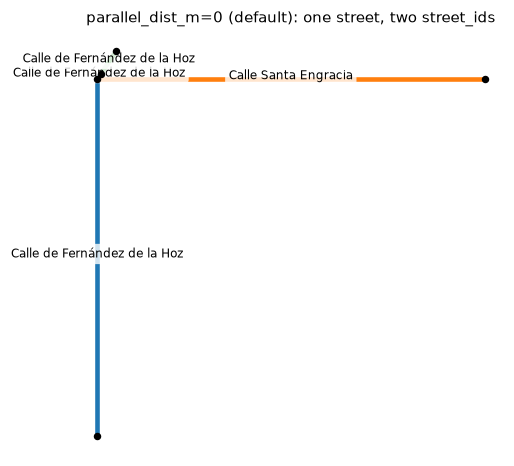

In [15]:
G = new_graph()
add_oneway_edge(G, 1, 2, (0, 0), (0, 950), highway="residential", name="Calle de Fernández de la Hoz", osmid=1)
add_oneway_edge(G, 2, 1, (0, 950), (0, 0), highway="residential", name="Calle de Fernández de la Hoz", osmid=1)
add_oneway_edge(G, 2, 3, (0, 950), (1, 964), highway="residential", name="Calle de Fernández de la Hoz", osmid=2)
add_oneway_edge(G, 3, 2, (1, 964), (0, 950), highway="residential", name="Calle de Fernández de la Hoz", osmid=2)
add_oneway_edge(G, 3, 4, (1, 964), (5, 1026), highway="residential", name="Calle de Fernández de la Hoz", osmid=3)
add_oneway_edge(G, 4, 3, (5, 1026), (1, 964), highway="residential", name="Calle de Fernández de la Hoz", osmid=3)
# A same-named side street at the middle node - close enough in real
# OSM data (a divided avenue crossing, tagged with its own name too).
add_oneway_edge(G, 2, 5, (0, 950), (100, 950), highway="residential", name="Calle Santa Engracia", osmid=4)
add_oneway_edge(G, 5, 2, (100, 950), (0, 950), highway="residential", name="Calle Santa Engracia", osmid=4)

nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, equal_aspect=False,
             title="parallel_dist_m=0 (default): one street, two street_ids")
plt.show()

The middle segment (14m - within the default 15m `node_cluster_m`)
becomes a loop/connector edge between the two real segments' node
cluster, so it never goes through ordinary name-matching, and
connector-bridging alone can't reconcile it with both neighbors at
once. With `parallel_dist_m=30`, it's close to, parallel with (nearly
collinear), and connected to (zero hops - it touches) both real
segments directly, so the parallel-street merge unifies all three into
one `street_id`, and the connector is treated as resolved rather than a
bare bridge.

,street_id,street_name,street_rank,highway,osmids
0,1,Calle de Fernández de la Hoz,5,residential,1;2;3
1,2,Calle Santa Engracia,5,residential,4


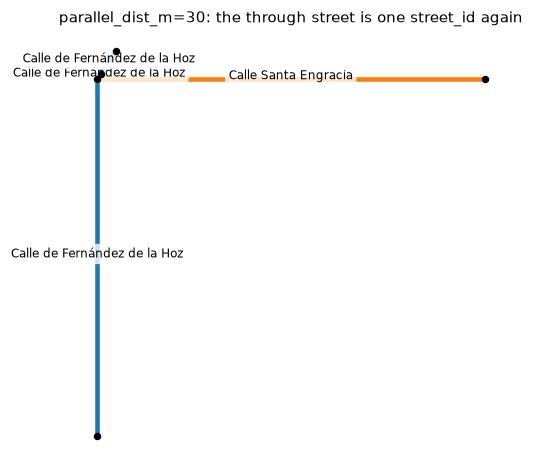

In [16]:
nodes_gdf, edges_gdf, streets_df = label(G, parallel_dist_m=30.0)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, equal_aspect=False,
             title="parallel_dist_m=30: the through street is one street_id again")
plt.show()

### A roundabout-style connector

A short, unnamed service-road segment (e.g. a roundabout slip lane)
often connects two nodes only a few meters apart, well inside one
intersection cluster. Rather than reasoning about its own name or rank,
it simply bridges whichever street_id already touches that cluster: it
takes on the *primary* arm's id here, not the *residential* one, since
a connector prefers the higher-priority (lower street_rank) neighbor
when more than one is present.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,1
1,2,None,5,residential,1


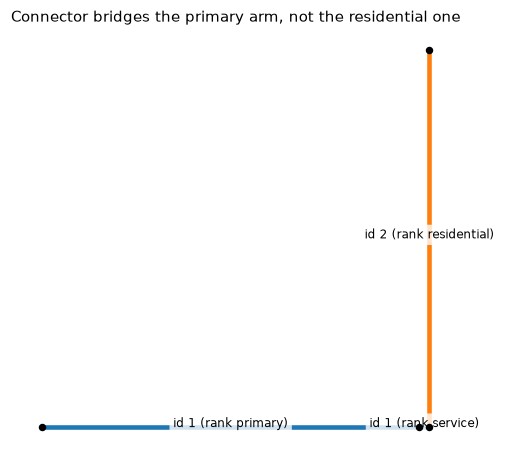

In [17]:
G = new_graph()
add_oneway_edge(G, 0, 1, (-300, 0), (0, 0), highway="primary")
add_oneway_edge(G, 1, 0, (0, 0), (-300, 0), highway="primary")
add_oneway_edge(G, 1, 2, (0, 0), (8, 0), highway="service")  # the connector
add_oneway_edge(G, 2, 1, (8, 0), (0, 0), highway="service")
add_oneway_edge(G, 2, 3, (8, 0), (8, 300), highway="residential")
add_oneway_edge(G, 3, 2, (8, 300), (8, 0), highway="residential")

nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, show_rank=True,
             title="Connector bridges the primary arm, not the residential one")
plt.show()

### An isolated connector gets no street_id at all

If a connector's cluster touches nothing else with a resolved
street_id (nothing real approaches it), it isn't minted an id of its
own. A bare stub like this isn't really a street. It's left with
`street_id = <NA>`, drawn as a thin dotted line below, and it doesn't
appear in `streets_df` at all.

,street_id,street_name,street_rank,highway,osmids


u   v   key
10  11  0      <NA>
11  10  0      <NA>
Name: street_id, dtype: Int64


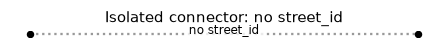

In [18]:
G = new_graph()
add_oneway_edge(G, 10, 11, (0, 0), (8, 0), highway="service")
add_oneway_edge(G, 11, 10, (8, 0), (0, 0), highway="service")

nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
print(edges_gdf["street_id"])
plot_streets(edges_gdf, nodes_gdf, title="Isolated connector: no street_id")
plt.show()

Both node-clustering rules, and the same-name Y-fork a few cells up,
are really the same underlying guarantee at work: no matter which rule
assigned a street_id, at most two edges may ever share one at a single
node. See [`report/street_identity.md`](../../report/street_identity.md)
"No more than two edges per node" for the full write-up, including how
a node with more than two is resolved (the shortest branch is cut into
a new id).

## Putting it together: an idealized street grid

`osmaddresssystem.synthetic_grid` builds a square 4x4 grid. Unnamed residential rows and columns, one named row
("Elm Street"), and one row upgraded to `primary`.

Every row collapses to a single street regardless of how many
intersections it crosses. That's 4 row streets. Every column is cut in
two where it crosses the interior primary row. That's 8 column
streets. 12 streets total, from what would otherwise be 24 separate
segments.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,2813760;5978899;7694403
1,2,None,5,residential,522560;5641917;6376432
2,3,None,5,residential,6409796;7201590
3,4,None,5,residential,1290439;2082233
4,5,None,5,residential,3834965;6242828
5,6,None,5,residential,366729;1158523
6,7,Elm Street,5,residential,6902609;9218251;9730766
7,8,None,5,residential,6640361
8,9,None,5,residential,9746116
9,10,None,5,residential,4626759


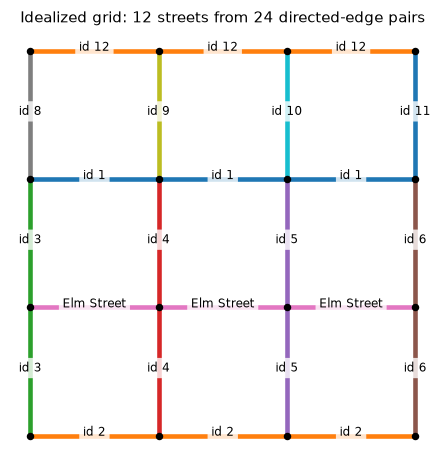

In [19]:
G = build_idealized_grid(rows=4, cols=4, spacing=120.0, named_row=1,
                          named_row_name="Elm Street", primary_row=2)
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Idealized grid: 12 streets from 24 directed-edge pairs")
plt.show()

Each color above is one `street_id` spanning every intersection it
passes through. OSM-style data would otherwise give each of the 24
segments its own disconnected identity.

## A less idealized grid

Real streets are rarely dead straight. the irregular grid builder
zigzags every row by ±10° segment to segment (under the threshold),
instead of running due east. One row also gets a permanent 35° bend
partway across (over the threshold).

Every gently-wiggling row is still one street. The bent row splits
into exactly two streets, not three, since only the single transition
into the bend exceeds 20°. Every column still splits where it crosses
the primary row, same as before.

,street_id,street_name,street_rank,highway,osmids
0,1,None,2,primary,630658;5978899;6902609;9218251
1,2,Elm Street,5,residential,522560;3434373;5641917;6376432
2,3,None,5,residential,6286570
3,4,None,5,residential,1405927
4,5,None,5,residential,612422
5,6,None,5,residential,7186462
6,7,None,5,residential,5494776
7,8,None,5,residential,2926432;4080658
8,9,None,5,residential,1138599;5602874
9,10,None,5,residential,3850142;6394668


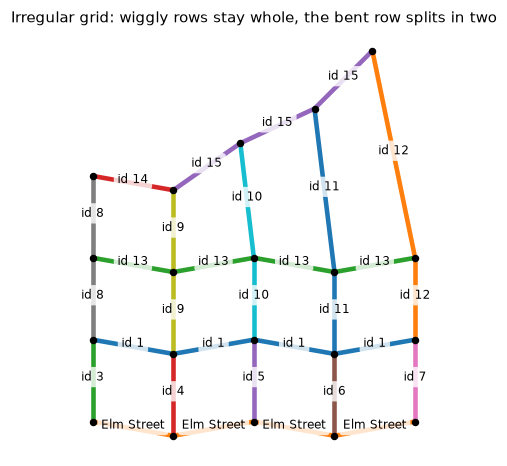

In [20]:
G = build_irregular_grid(rows=4, cols=5, wiggle_deg=10.0, kink_row=3, kink_col=2, kink_deg=35.0)
nodes_gdf, edges_gdf, streets_df = label(G)
display(streets_df)
plot_streets(edges_gdf, nodes_gdf, title="Irregular grid: wiggly rows stay whole, the bent row splits in two")
plt.show()